# Design a card, measure whether it is balanced, then give it art

In [1]:
from pathlib import Path
import os, sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "teklo").is_dir())
sys.path.insert(0, str(ROOT))

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")                      
print("HF token loaded:", bool(os.environ.get("HF_TOKEN")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import teklo
from teklo.cards import Card, Effects
from teklo.engine import evaluate_deck
from teklo.plotting import BLUE, ORANGE, RED, use_style

use_style()

HF token loaded: True


# LOAD Cards

In [2]:
cards = teklo.load_cards(ROOT / "notebooks" / "card.csv", ROOT / "custom_cards.csv")
pool = teklo.teklo_pool(cards)       # what a Teklovossen deck may play
generic = teklo.generic_pool(cards)  # what the reference opponent plays
table = teklo.cards_frame(pool)

print(f"{len(pool)} cards a Teklovossen deck can use, {table.custom.sum()} of them fan-made")
table.pivot_table(index="theme", columns="kind", values="id", aggfunc="count", fill_value=0)

698 cards a Teklovossen deck can use, 34 of them fan-made


kind,action,attack,evo,instant,item
theme,,,,,
AI,0,0,0,0,4
Bio,1,0,8,0,6
Generic,99,223,0,37,28
Mechanologist,34,164,33,1,49
Nano,1,0,5,1,2
Quantum,0,0,2,0,0


# Write a Dream cards

In [3]:
my_text = "If Quantum Pulse hits, draw a card."
my_card = Card(
    id="Quantum Pulse (1)",      # name + pitch in brackets, must be unique
    name="Quantum Pulse",
    kind="attack",               # attack, action, instant, item or evo
    cost=1,                      # resources to play it
    pitch=1,                     # 1 = red, 2 = yellow, 3 = blue
    power=4,                     # damage if it hits
    defense=3,                   # how much it blocks from your hand
    slot=None,                   # only for evo cards: head, chest, arms or legs
    theme="Quantum",             # AI, Nano, Quantum or Bio
    custom=True,                 # True = a fan-made (dream) card
    keywords=("Go again",),
    text=my_text,
    effects=Effects(go_again=True, draw=1),   # what the simulator will actually do
)
my_card

Card(id='Quantum Pulse (1)', name='Quantum Pulse', kind='attack', cost=1, pitch=1, power=4, defense=3, slot=None, theme='Quantum', custom=True, keywords=('Go again',), text='If Quantum Pulse hits, draw a card.', effects=Effects(go_again=True, boost=False, power_bonus=0, draw=1, energy=0, damage=0, life=0))

## Check: does the simulator read the card the way I wrote it?

`effects` above was written by hand. The project also has a parser that reads rules text and
turns it into effects (it is how the 34 fan-made cards from `custom_cards.csv` got theirs).
If both agree, the rules text says exactly what the simulator will play.

In [4]:
parsed = teklo.parse_effects(my_card.text, keywords=my_card.keywords, kind=my_card.kind)
print("written by hand:", my_card.effects)
print("parsed from text:", parsed)
print("match:", parsed == my_card.effects)

written by hand: Effects(go_again=True, boost=False, power_bonus=0, draw=1, energy=0, damage=0, life=0)
parsed from text: Effects(go_again=True, boost=False, power_bonus=0, draw=1, energy=0, damage=0, life=0)
match: True


The parser only knows a few phrases: `Go again`, `Boost`, `+N power`, `draw a card`,
`gain N{r}` or `gain N Teklo Energy`, `deal N damage` and `gain N{h}` (life).
Anything else is flavour to the simulator, so it cannot be balanced either.

## A small set of dream cards

Writing `effects` by hand twice is how mistakes slip in. This helper builds a card from its
rules text and lets the parser fill in `effects`, so the text and the simulation can never disagree.

In [5]:
def dream_card(name, kind, cost, pitch, theme, text, power=0, defense=0, slot=None, keywords=()):
    """A fan-made card whose effects come from its own rules text."""
    return Card(
        id=f"{name} ({pitch})", name=name, kind=kind, cost=cost, pitch=pitch,
        power=power, defense=defense, slot=slot, theme=theme, custom=True,
        keywords=tuple(keywords), text=text,
        effects=teklo.parse_effects(text, keywords=tuple(keywords), kind=kind),
    )


dream = [
    my_card,
    dream_card("Evo Quantum Lens", "evo", cost=0, pitch=3, theme="Quantum", slot="head", defense=1,
               text="At the start of your turn, gain 1 Teklo Energy."),
    dream_card("AI Overclock Core", "item", cost=1, pitch=2, theme="AI",
               text="At the start of your turn, the next attack action card you play this turn gains +1{p}."),
    dream_card("Nano Mender Swarm", "instant", cost=0, pitch=3, theme="Nano",
               text="Gain 2{h}. Draw a card."),
    dream_card("Bio Graft Surge", "action", cost=1, pitch=2, theme="Bio", defense=2,
               keywords=("Go again",), text="Your next attack this turn gains +2{p}. Draw a card."),
    dream_card("Nano Tech Protocol Hive", "action", cost=0, pitch=1, theme="Nano", defense=3,power=1,
               keywords=("Go again",), text="Whan this attack, search your deck for a Nano Evo, who have cost equal to the number of Evo equiped")
]

fx_cols = ["fx_go_again", "fx_boost", "fx_power_bonus", "fx_draw", "fx_energy", "fx_damage", "fx_life"]
teklo.cards_frame(dream)[["id", "kind", "theme", "cost", "pitch", "power", "defense", *fx_cols]]

,id,kind,theme,cost,pitch,power,defense,fx_go_again,fx_boost,fx_power_bonus,fx_draw,fx_energy,fx_damage,fx_life
0,Quantum Pulse (1),attack,Quantum,1,1,4,3,True,False,0,1,0,0,0
1,Evo Quantum Lens (3),evo,Quantum,0,3,0,1,False,False,0,0,1,0,0
2,AI Overclock Core (2),item,AI,1,2,0,0,False,False,1,0,0,0,0
3,Nano Mender Swarm (3),instant,Nano,0,3,0,0,False,False,0,1,0,0,2
4,Bio Graft Surge (2),action,Bio,1,2,0,2,True,False,2,1,0,0,0
5,Nano Tech Protocol Hive (1),action,Nano,0,1,1,3,True,False,0,0,0,0,0


Read the table as the simulator sees each card. Every dream card has at least one non-zero
effect, unlike most cards in `custom_cards.csv`, which only store a type line.

**Try it:** change a text (for example `Gain 2 life` instead of `Gain 2{h}`) and rerun.
The `fx_life` column drops to 0: the parser did not understand it.

## The card template

`teklo/card_art.py` draws each card on a frame cut from the ChatGPT concept art in `evos/`.
The concept card's own title, text, numbers and picture were wiped out, leaving a blank frame per
theme in `evos/frames/` (AI, Nano, Quantum and Bio). The card's name, cost, power, defense, type line
and rules text are written on it, the picture shows through the art window, and the gem takes the
pitch colour (red 1, yellow 2, blue 3). Mechanologist and Generic cards, which have no concept art,
get a simpler frame drawn in the theme colour.

All the lettering is drawn by Pillow. Image models garble text, so the model is only asked for the
picture. Without art, the template shows a placeholder glow, so the layout can be checked for free.

**After editing `teklo/card_art.py`, restart the kernel.** Python keeps the module it imported first,
so rerunning the cells alone still draws with the old code.

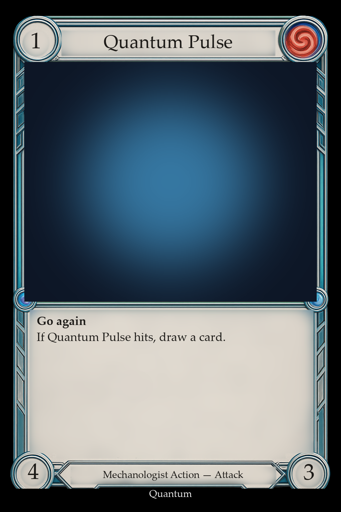

In [6]:
from teklo.card_art import generate_art, render_card, slug

render_card(my_card).resize((341, 512))

## Art for the cards: Hugging Face Inference Providers

The illustration comes from an open text-to-image model, **FLUX.1-schnell** (Apache 2.0 licence),
run by an Inference Provider through the Hugging Face API. `provider="auto"` lets Hugging Face pick
a provider that serves the model; the call is paid with the `HF_TOKEN` loaded at the top
(a few cents at most for this set).

Each card gets an *art idea* (what to draw) and a *flavour* line (the italic text on the card).
`generate_art` adds the theme's visual style to the idea (`THEME_STYLE` in `card_art.py`: it
changes the picture only, never the frame) and saves the image and a JSON note
(model, prompt, seed) to `evos/generated/`. A saved card is reused instead of paid for again;
pass `overwrite=True` to draw a new one, or change the seed.

In [7]:
ART_MODEL = "black-forest-labs/FLUX.1-schnell"
OUT = ROOT / "evos" / "generated"

ideas = {
    "Quantum Pulse (1)": "A mechanical gauntlet of dark steel plates firing a pulse of blue quantum light",
    "Evo Quantum Lens (3)": "A sleek steel helmet with a glowing blue crystal lens over one eye",
    "AI Overclock Core (2)": "A floating cube-shaped processor core with cyan circuits overheating with light",
    "Nano Mender Swarm (3)": "A cloud of tiny silver nanites knitting a cracked metal armour plate back together",
    "Bio Graft Surge (2)": "A mechanical arm with green bioluminescent living tissue growing through its joints",
    "Nano Tech Protocol Hive (1)" : " A programm Screen with Nano tech armor on it , like a blue print schematics",
}
flavour = {
    "Quantum Pulse (1)": "Every outcome is already in the machine.",
    "Evo Quantum Lens (3)": "It sees the move before the move exists.",
    "AI Overclock Core (2)": "Safety limits are a suggestion.",
    "Nano Mender Swarm (3)": "Nothing Teklovossen builds stays broken.",
    "Bio Graft Surge (2)": "Steel learns to grow.",
    "Nano Tech Protocol Hive (1)" : " The Swarm are real",
}
assert set(ideas) == {c.id for c in dream}, "every dream card needs an art idea"

In [8]:
from huggingface_hub import InferenceClient

client = InferenceClient(provider="auto", api_key=os.environ["HF_TOKEN"])
CREDIT = "Teklo Study dream card \u2014 art: FLUX.1-schnell via Hugging Face (AI-generated)"

for seed, card in enumerate(dream):
    art = generate_art(client, card, ideas[card.id], OUT, model=ART_MODEL, seed=seed)
    render_card(card, art, flavour=flavour[card.id], credit=CREDIT).save(OUT / f"{slug(card)}.png")
    print("saved", (OUT / f"{slug(card)}.png").relative_to(ROOT))

saved evos\generated\quantum_pulse_1.png
saved evos\generated\evo_quantum_lens_3.png


saved evos\generated\ai_overclock_core_2.png


saved evos\generated\nano_mender_swarm_3.png
saved evos\generated\bio_graft_surge_2.png


saved evos\generated\nano_tech_protocol_hive_1.png


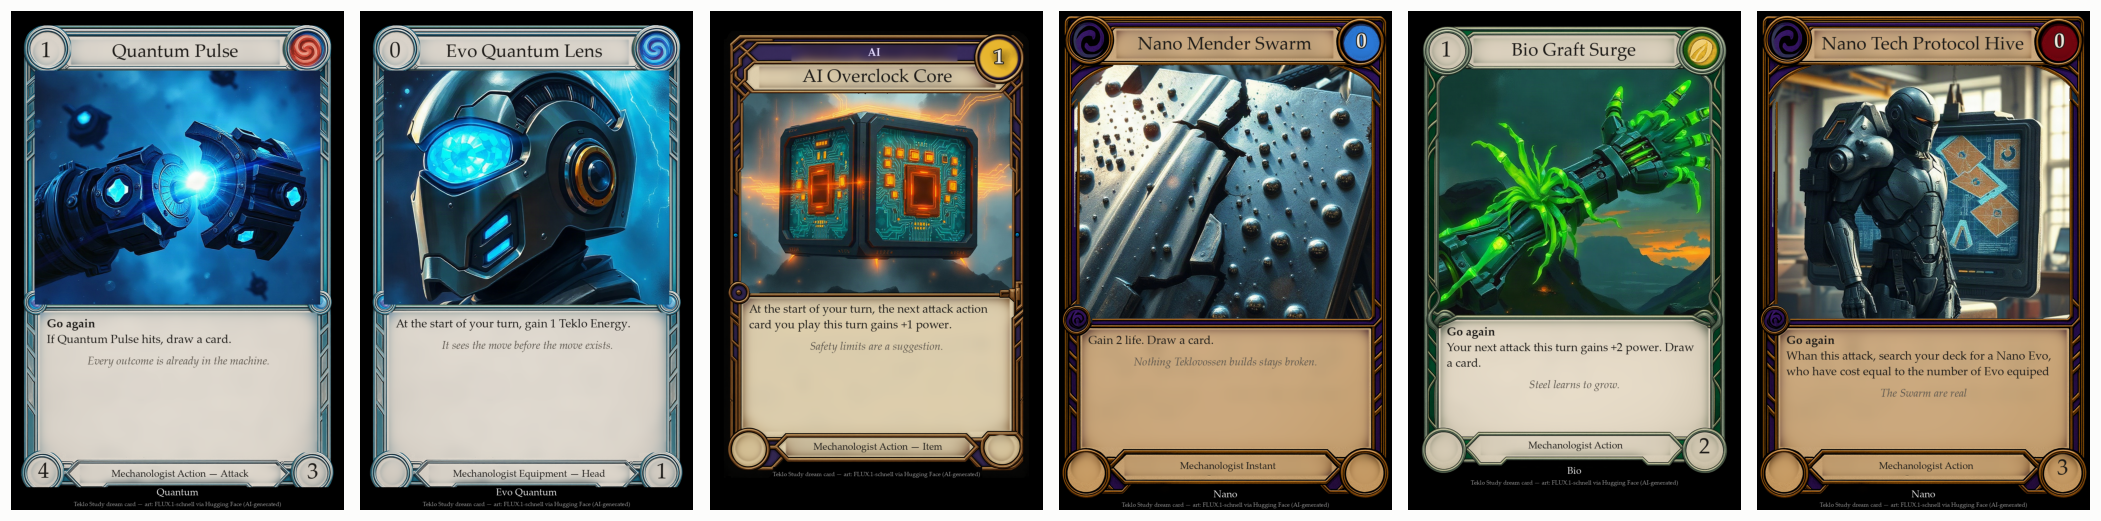

In [9]:
from PIL import Image

fig, axes = plt.subplots(1, len(dream), figsize=(3.2 * len(dream), 5))
for ax, card in zip(axes, dream):
    ax.imshow(Image.open(OUT / f"{slug(card)}.png"))
    ax.axis("off")
fig.tight_layout()

## What we have, and what comes next

- Six dream cards whose rules text and simulated effects agree.
- Cards drawn on frames cut from the concept art, with every card's text spelled correctly.
- Art from an open model, saved with its prompt and seed, and credited on the card itself.

**Next lesson: is each card balanced?** Play the same random Teklovossen decks twice against the
reference opponent, once with the dream card and once with a plain card of the same cost in its place,
and compare the win rates. A balanced card should move the win rate a little, not a lot.